## Исследование регистрируемой безработицы в России.

<b>Задача:</b>
Для составления аналитического обзора по проблеме безработицы в России необходимо провести исследование основных социально-демографических характеристик безработных и ситуацию в 2020 году.<br>

<b>Источник данных:</b><br>
Регистрируемая безработица в России: общие социально-демографические характеристики с детализацией до органа занятости населения // Роструд; обработка: Колесников И.В., Копыток В.К., Кузьмина Ю.В., Инфраструктура научно-исследовательских данных, АНО «ЦПУР», 2021. Доступ: открытая лицензия в исследовательских целях. Размещено: 21.10.2021. (Ссылка на набор данных: http://data-in.ru/data-catalog/datasets/180/)

<b>Описание данных:</b><br>

## <b>Задание:</b>

### <a class='anchor' id='1'></a> Загрузка данных. Предобработка

1. Загрузите файл <code>unemployed.csv</code> с разделителем <code>;</code>
2. Определите размер датасета.
3. Познакомьтесь с данными.
4. Проверьте пропуски, дубликаты и типы данных.
5. Добавьте столбцы с месяцем и годом (year, month).
6. Сформулируйте выводы.

###  <a class='anchor' id='1'></a> Исследовательский анализ данных

Все отчеты в этом разделе должны быть визуализированы. Графики должны содержать названия и подписи осей. Каждый пункт сопровидите выводами.

1. Определите динамику числа обращений в службу занятости за представленный в датасете период. Постройте линейный график. Укрупните по годам. Постройте столбчатую диаграмму. Добавьте признак повторных обращений в центры занятости населения, Постройте линейный график.
2. Определите число обращений в службу занятости по возрастным группам. Постройте столбчатую диаграмму.<br> Детализируйте по каждому году, визуализируйте результат.
3. Определите общее число устроившихся на работу граждан, определите процент трудоустройства по всему датасету. Постройте столбчатую диаграмму.
4. Определите соотношение трудоустройства по каждому году (в абсолютных значениях). Постройте столбчатую диаграмму.<br>
Выполните в относительных значениях, оцените динамику процента трудоустройства по годам.
5. Осуществите категоризацию по столбцам <code>gender</code> и <code>education</code> в соответствии с исходными данными. Определите с каким образованием в службу занятости обращаются гражданине, ранее официально не работавшие. Определите соотношение трудоустройства по каждому уровню образования.
6. Исследуйте безработицу в России отдельно за 2020 год (за исключением декабря 2020!). Создайте срез данных.<br>

6.1 Определите динамику числа безработных и нашедших работу за 2020 год по месяцам.<br>
6.2 Определите процент трудоустройства по гендерной принадлежности<br>
6.3 Определите число обращений в службу занятости по федеральным округам.<br>
6.4 Определите разброс числа объявлений по регионам с помощью boxplot.<br>
6.5 Определите число обращений в службу занятости в Северо-Западном федеральном округе по регионам.<br>
6.6 Определите процент трудоустройства по федеральным округам.<br>
6.7 Определите процент трудоустройства по регионам для каждого федерального округа. Реализуйте в цикле<br>




### Загрузка данных и предобработка

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt

In [2]:
df = pd.read_csv('unemployed.csv', sep=';')

In [3]:
sns.set_theme(style='darkgrid')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4347416 entries, 0 to 4347415
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   id                 int64  
 1   district           object 
 2   region             object 
 3   month_application  object 
 4   changed_value      bool   
 5   age                object 
 6   gender             float64
 7   education          float64
 8   hc_repeat          bool   
 9   hc_didnotwork      bool   
 10  find_new_job       bool   
 11  count              int64  
dtypes: bool(4), float64(2), int64(2), object(4)
memory usage: 281.9+ MB


In [4]:
df.duplicated().sum()

0

In [5]:
df.head(1)

,id,district,region,month_application,changed_value,age,gender,education,hc_repeat,hc_didnotwork,find_new_job,count
0,1170,Дальневосточный федеральный округ,Амурская область,2017-01,False,52-57,0.0,4.0,True,False,False,1


In [6]:
# через info не отображаются пропуски, проверим по каждому столбцу отдельно
for i in df.columns:
    print(i, df[i].isnull().sum())

id 0
district 0
region 0
month_application 0
changed_value 0
age 0
gender 8
education 339215
hc_repeat 0
hc_didnotwork 0
find_new_job 0
count 0


In [7]:
# заполоним пропуски в столбце education нулями (по описанию)
df['education'].fillna(0, inplace=True)

In [8]:
# рассмотрим пропуски в столбце gender
df.query('gender.isnull()')

,id,district,region,month_application,changed_value,age,gender,education,hc_repeat,hc_didnotwork,find_new_job,count
600269,521970,Приволжский федеральный округ,Оренбургская область,2017-01,False,40-45,NaN,3.0,True,False,False,1
2156738,2182523,Северо-Кавказский федеральный округ,Чеченская Республика,2020-10,True,16-21,NaN,0.0,False,False,True,1
2156739,2183055,Северо-Кавказский федеральный округ,Чеченская Республика,2020-10,True,22-27,NaN,0.0,False,False,False,1
2156788,2184993,Северо-Кавказский федеральный округ,Чеченская Республика,2020-10,True,46-51,NaN,0.0,False,False,False,1
2160397,2177422,Северо-Кавказский федеральный округ,Чеченская Республика,2020-08,True,28-33,NaN,0.0,False,False,False,1
3260801,3240101,Уральский федеральный округ,Ханты-Мансийский автономный округ - Югра,2018-03,False,34-39,NaN,6.0,True,False,True,1
3337760,3402610,Уральский федеральный округ,Челябинская область,2020-10,False,46-51,NaN,4.0,True,False,False,1
4118284,4087928,Южный федеральный округ,Волгоградская область,2019-06,False,52-57,NaN,3.0,True,False,False,1


In [9]:
# т.к. 8 строк из всей выборки - это очень малое кол-во, я принял решение удалить эти 8 строк, чтобы не искажать данные
df.drop(df[df['gender'].isnull()].index, inplace=True)

In [10]:
# удалилось 8 строк, как и нужно
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4347408 entries, 0 to 4347415
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   id                 int64  
 1   district           object 
 2   region             object 
 3   month_application  object 
 4   changed_value      bool   
 5   age                object 
 6   gender             float64
 7   education          float64
 8   hc_repeat          bool   
 9   hc_didnotwork      bool   
 10  find_new_job       bool   
 11  count              int64  
dtypes: bool(4), float64(2), int64(2), object(4)
memory usage: 315.1+ MB


In [11]:
# изменим тип столбцов gender и education на int32, чтобы избавиться от дробной части (.0)
df['gender'] = df['gender'].astype('int32')
df['education'] = df['education'].astype('int32')

In [12]:
# чтобы в дальнейшем применять атрибуты datetime поменял тип данных столбца month_application на datetime64
# (не знал, как убрать день по-другому, нашел такой способ)
df['month_application'] = pd.to_datetime(df['month_application'], format='%Y-%m')
df['month_application'] = df['month_application'].dt.to_period('M')

In [13]:
# создаем два столбца с годом и месяцем
df['year'] = df['month_application'].dt.year
df['month'] = df['month_application'].dt.month

In [14]:
df.head(1)

,id,district,region,month_application,changed_value,age,gender,education,hc_repeat,hc_didnotwork,find_new_job,count,year,month
0,1170,Дальневосточный федеральный округ,Амурская область,2017-01,False,52-57,0,4,True,False,False,1,2017,1


In [15]:
# проверим данные на корректность
len(df['region'].unique())

85

In [16]:
df['month_application'].max()

Period('2020-12', 'M')

In [17]:
df['age'].unique()

array(['52-57', '22-27', '34-39', '40-45', '46-51', '58-60', '16-21',
       '28-33'], dtype=object)

In [18]:
df['gender'].unique()

array([0, 1])

In [19]:
df['education'].unique()

array([4, 2, 1, 3, 6, 9, 0])

In [20]:
df['district'].unique()

array(['Дальневосточный федеральный округ',
       'Приволжский федеральный округ',
       'Северо-Западный федеральный округ',
       'Северо-Кавказский федеральный округ',
       'Сибирский федеральный округ', 'Уральский федеральный округ',
       'Центральный федеральный округ', 'Южный федеральный округ'],
      dtype=object)

**Вывод**\
До обработки данных я познакомился с данными: описанием столбцов и общей информацией о датасете.
В ходе обработки данных я выяснил, что явных дубликатов нет. Там, где было необходимо, заполнил пустые значения. Несколько строк с пустыми значениями удалил. Также данные были проверены на корректность. У 3-х столбцов был поменян тип для удобства дальнейших вычислений. Добавлены два новых столбца с годом и месяцем. 
Данные успешно загружены, очищены и подготовлены для дальнейшего анализа.

### Динамика обращений в службу занятости
Определите динамику числа обращений в службу занятости за представленный в датасете период. Постройте линейный график. Укрупните по годам. Постройте столбчатую диаграмму. Добавьте признак повторных обращений в центры занятости населения, Постройте линейный график.

In [21]:
df.head(1)

,id,district,region,month_application,changed_value,age,gender,education,hc_repeat,hc_didnotwork,find_new_job,count,year,month
0,1170,Дальневосточный федеральный округ,Амурская область,2017-01,False,52-57,0,4,True,False,False,1,2017,1


In [22]:
# построим сводную таблицу числа обращений по месяцам
count_month = df.pivot_table(index='month_application', aggfunc='sum', values='count').head(47) # убрал декабрь из-за неполных данных (всего 7 тысяч обращений)
# count_month.columns = ['month_application', 'count']
count_month.tail(5)

,count
month_application,
2020-07,657621
2020-08,538154
2020-09,417303
2020-10,372160
2020-11,277431


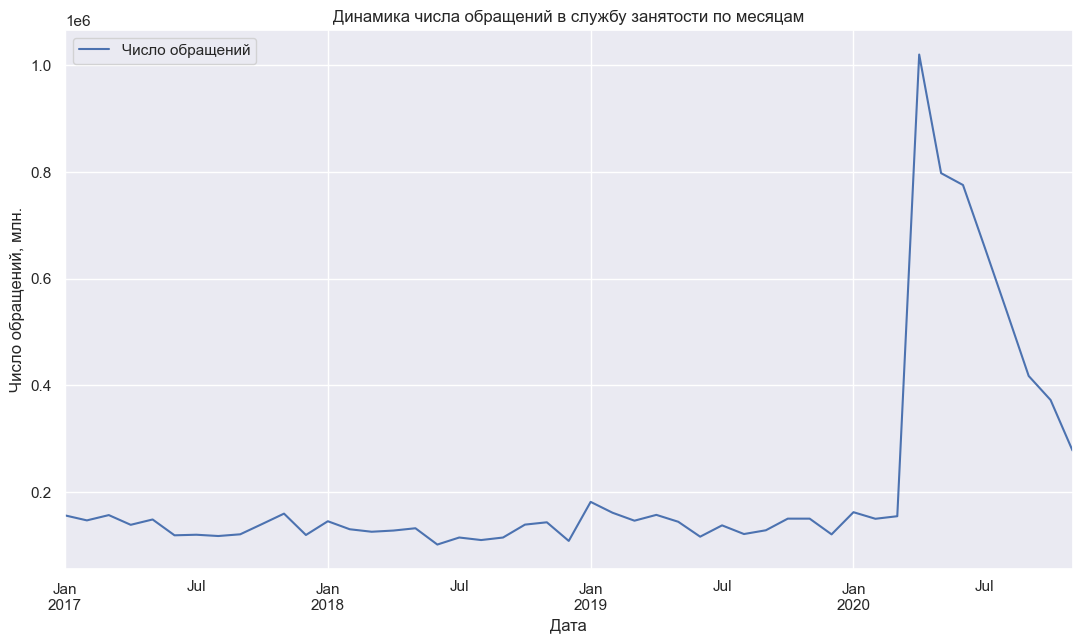

In [23]:
# построим линейный график на основе полученной таблицы
count_month.plot(figsize = (13,7),
                 title='Динамика числа обращений в службу занятости по месяцам',
                 xlabel='Дата',
                 ylabel='Число обращений, млн.')
plt.legend(['Число обращений'])
plt.show()

На графике видно, что в течение 2017-2019 годов рынок труда демонстрировал стабильность с положительной динамикой — число обращений в службу занятости имело сезонные колебания, но в целом немного снижалось. Однако в 2020 году эта позитивная тенденция была резко нарушена глобальным экономическим шоком, вызванным пандемией COVID-19, что привело к росту безработицы и числа обращений за помощью в трудоустройстве.

,count
year,
2017,1636951
2018,1486266
2019,1708623
2020,5358366


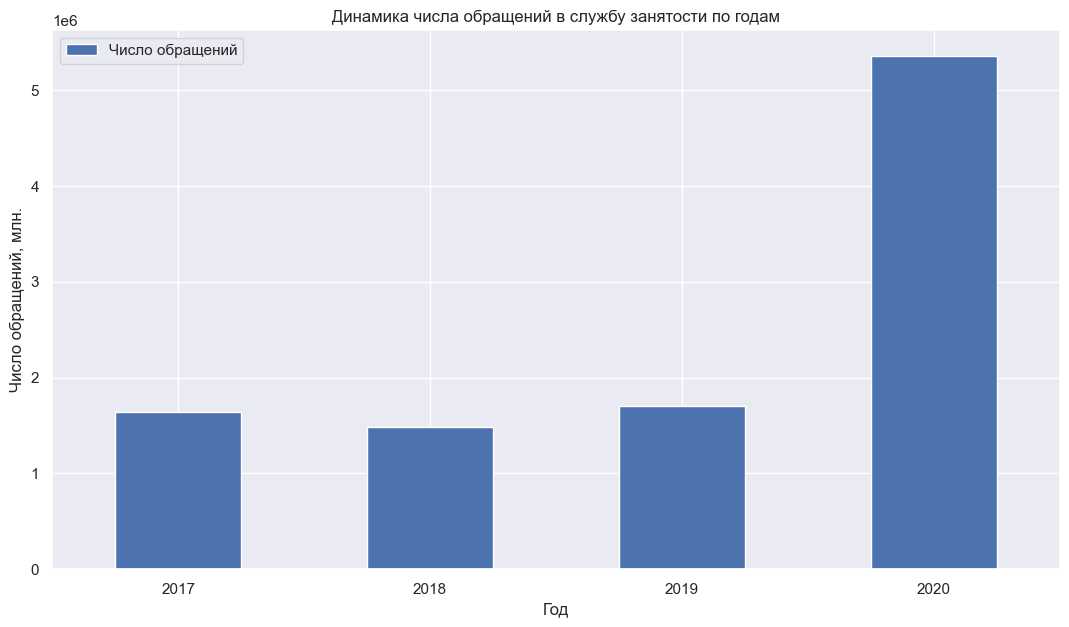

In [24]:
# Укрупним по годам: сделаем сводную таблицу и построим столбчатую диаграмму
count_year = df.pivot_table(index='year', aggfunc='sum', values='count')
display(count_year.head(5))
count_year.plot(kind='bar',
                figsize = (13,7),
                title='Динамика числа обращений в службу занятости по годам',
                rot=0,
                xlabel='Год',
                ylabel='Число обращений, млн.')
plt.legend(['Число обращений'])
plt.show()

Данная диаграмма подтверждает наш первоначальный анализ. Мы видим, что относительно умеренный рост обращений в 2017-2019 годах сменился резким скачком в 2020 году.

hc_repeat,False,True
month_application,,
2020-07,419448,238173
2020-08,347747,190407
2020-09,268929,148374
2020-10,217689,154471
2020-11,154100,123331


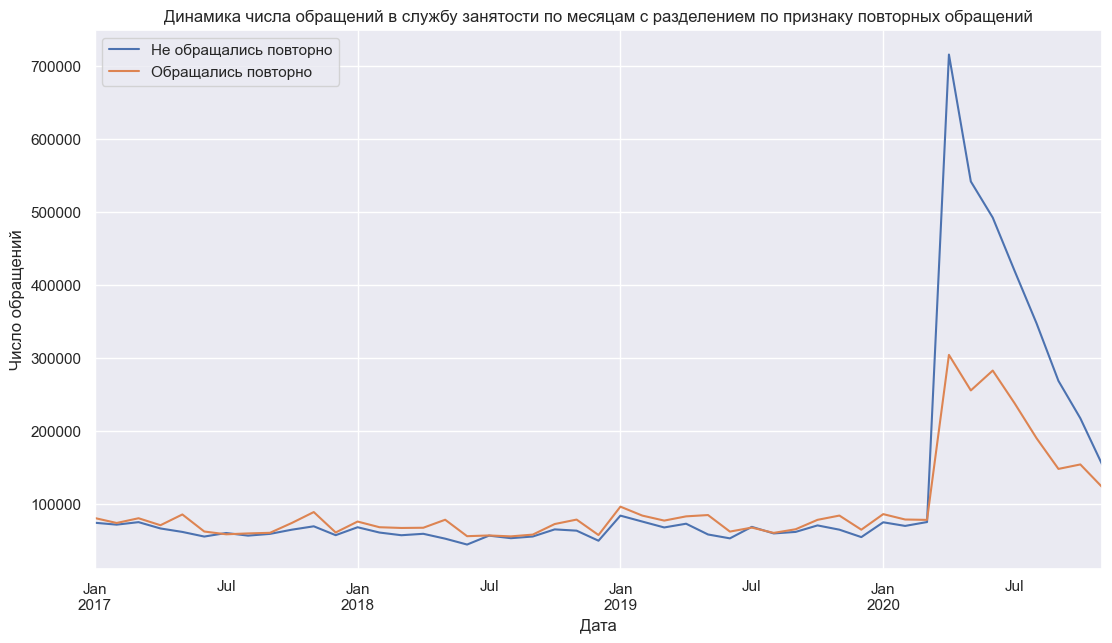

In [25]:
# добавим признак повторных обращений
count_month_repeat = df.pivot_table(index='month_application', columns='hc_repeat', aggfunc='sum', values='count').head(47)
display(count_month_repeat.tail(5))
count_month_repeat.plot(figsize = (13,7), 
                        title='Динамика числа обращений в службу занятости по месяцам с разделением по признаку повторных обращений',
                        xlabel='Дата',
                        ylabel='Число обращений')
plt.legend(['Не обращались повторно', 'Обращались повторно'])
plt.show()

Во время пандемии COVID-19 рост повторных обращений в службы занятости был менее значительным по сравнению с первичными по нескольким причинам. Экономический спад и ограничительные меры привели к массовым увольнениям впервые для многих граждан, что вызвало резкий всплеск первичных обращений. В то же время люди, уже состоявшие на учете, столкнулись с заморозкой вакансий и замедлением трудоустройства, но их численный рост был ограничен исходным размером этой группы. Часть повторно обращающихся могла перейти в категорию длительной безработицы или найти альтернативные источники дохода, тогда как первичные обращения отражали внезапную и массовую потерю рабочих мест в ранее стабильных отраслях.

### Анализ обращений в службу занятости по возрастным группам
Определите число обращений в службу занятости по возрастным группам. Постройте столбчатую диаграмму. Детализируйте по каждому году, визуализируйте результат.

In [26]:
df.head(1) #вывожу просто для наглядности

,id,district,region,month_application,changed_value,age,gender,education,hc_repeat,hc_didnotwork,find_new_job,count,year,month
0,1170,Дальневосточный федеральный округ,Амурская область,2017-01,False,52-57,0,4,True,False,False,1,2017,1


,count
age,
16-21,642895
22-27,1314197
28-33,2001622
34-39,1963617
40-45,1580491
46-51,1325802
52-57,1066379
58-60,295203


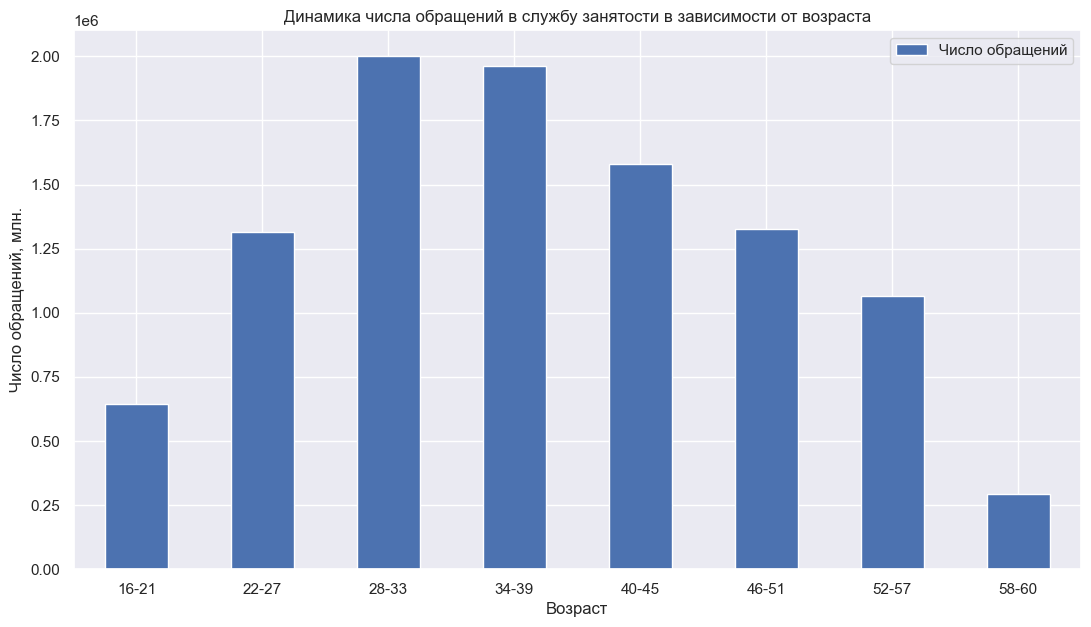

In [27]:
# построим сводную таблицу
count_age = df.pivot_table(index='age', aggfunc='sum', values='count')
display(count_age)
count_age.plot(kind='bar',
               figsize = (13,7),
               title='Динамика числа обращений в службу занятости в зависимости от возраста',
               rot=0,
               xlabel='Возраст',
               ylabel='Число обращений, млн.')
plt.legend(['Число обращений'])
plt.show()

Можно заметить, что число обращений растест до возраста 28-33, потом начинает плавно снижаться. Это связано с тем, что более молодые люди делают упор на образование и, зачастую, работают неофициально. Дальше происходит заметный рост, т.к. все эта молодешь потихоньку выпускается из учебных заведений и начинает искать работу. В возрастной группе 28-33 наблюдается пик - это значит, что люди часто сталкиваются с необходимостью смены работы, повышения квалификации или испытывают сложности с карьерным ростом. Дальше наступает возраст, когда люди уже находят постоянную работу, фиксируются на ней и число обращений плавно опускается.

year,2017,2018,2019,2020
age,,,,
16-21,122823,101361,100517,318194
22-27,202814,159944,170986,780453
28-33,276401,245414,289323,1190484
34-39,277531,261581,309486,1115019
40-45,252922,242501,279276,805792
46-51,235754,224407,255398,610243
52-57,218311,199209,229192,419667
58-60,50395,51849,74445,118514


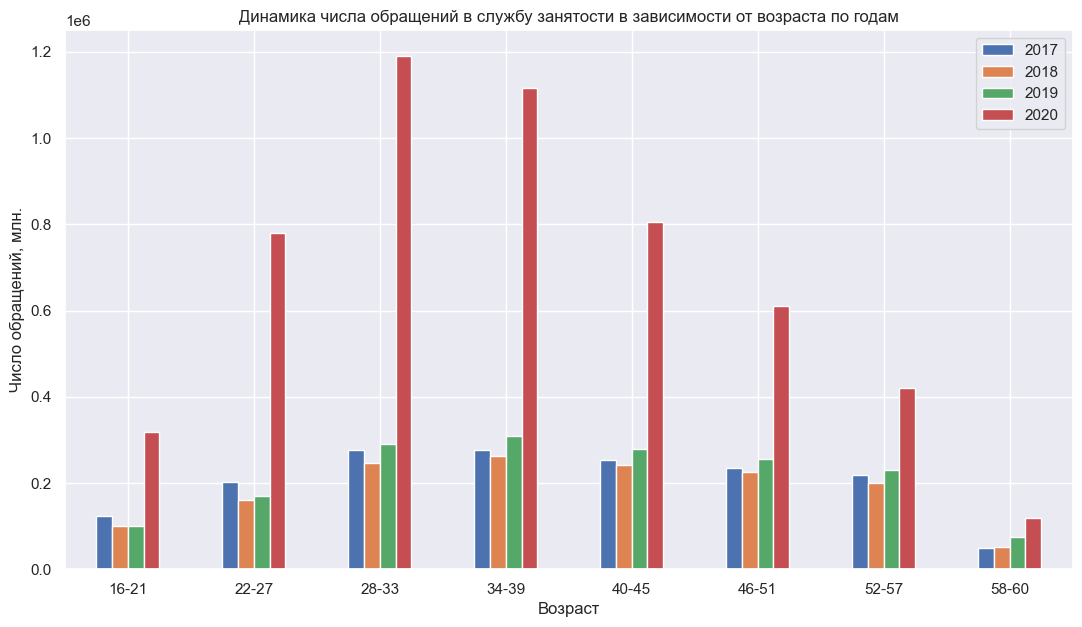

In [28]:
# детализируем по годам
count_age_year = df.pivot_table(index='age', columns='year', aggfunc='sum', values='count')
display(count_age_year)
count_age_year.plot(kind='bar',
               figsize = (13,7),
               title='Динамика числа обращений в службу занятости в зависимости от возраста по годам',
               rot = 0,
               xlabel='Возраст',
               ylabel='Число обращений, млн.')
plt.legend(['2017', '2018', '2019', '2020'])
plt.show()

По диаграмме видно, что все возрастные группы имеют схожую структуру динамики за исключением групп 16-21 и 58-60. Также можно заметить, что в 2020 году число обращений значительно выросло по всем возрастным группам, за исключением группы 58-60. В этой группе изменение примерно такое же, как и в 2019 году.

### Анализ эффективности трудоустройства граждан
Определите общее число устроившихся на работу граждан, определите процент трудоустройства по всему датасету. Постройте столбчатую диаграмму.

In [29]:
df.head(1)

,id,district,region,month_application,changed_value,age,gender,education,hc_repeat,hc_didnotwork,find_new_job,count,year,month
0,1170,Дальневосточный федеральный округ,Амурская область,2017-01,False,52-57,0,4,True,False,False,1,2017,1


In [30]:
# Найдём кол-во граждан, устроившихся на работу
n = df[df['find_new_job'] == True]['count'].sum()
N = df['count'].sum()
print(f"Кол-во граждан, устроившихся на работу = {n}\nПроцент по трудоустройству = {n/N*100:.1f}%")

Кол-во граждан, устроившихся на работу = 3576667
Процент по трудоустройству = 35.1%


,count
find_new_job,
False,6613539
True,3576667


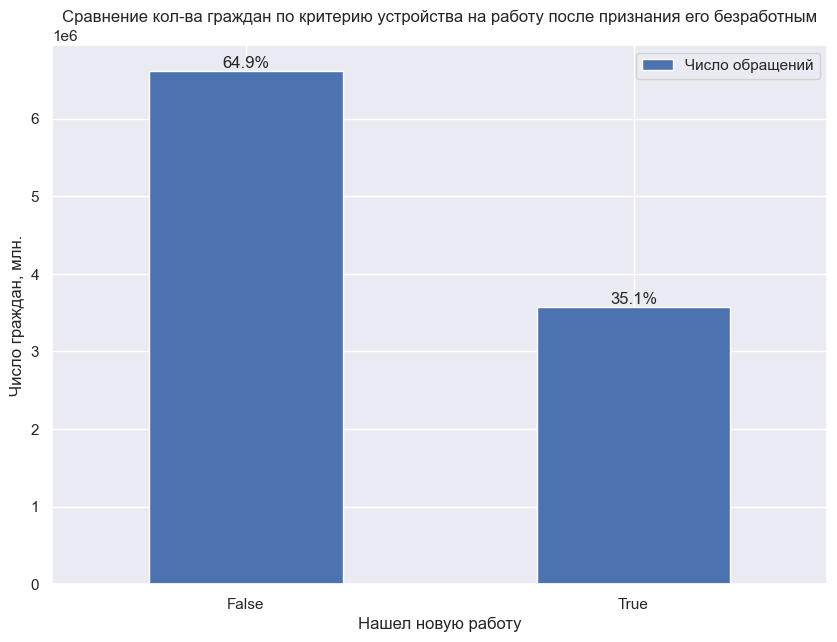

In [31]:
# Создадим сводную таблицу и построим диаграмму
find_nj = df.pivot_table(index='find_new_job', aggfunc='sum', values='count')
display(find_nj)
find_nj.plot(kind='bar',
               figsize = (10,7),
               title='Сравнение кол-ва граждан по критерию устройства на работу после признания его безработным',
               rot=0,
               xlabel='Нашел новую работу',
               ylabel='Число граждан, млн.')
# напишем цикл, который добавляет над столбцами значение в процентах
for i, v in enumerate(find_nj['count']):
    percent = (v/N) * 100
    plt.text(i, v, f'{percent:.1f}%', ha='center', va='bottom')
plt.legend(['Число обращений'])
plt.show()

На диаграмме видно, что около 35.1% граждан находят работу, после обращения в центр занятости. Это не самый лучший показатель, который свидетельствует о работе службы занятости, но оставляет пространство для улучшения. В идеале эффективность должна стремиться к 60-70%, особенно для мотивированных соискателей с востребованными профессиями. Показатель можно считать удовлетворительным, но не оптимальным - примерно каждый второй обратившийся находит работу через службу занятости.

### Анализ соотношения трудоустройства граждан по каждому году
Определите соотношение трудоустройства по каждому году (в абсолютных значениях). Постройте столбчатую диаграмму.
Выполните в относительных значениях, оцените динамику процента трудоустройства по годам.

find_new_job,False,True
year,,
2017,761182,875769
2018,696596,789670
2019,894742,813881
2020,4261019,1097347


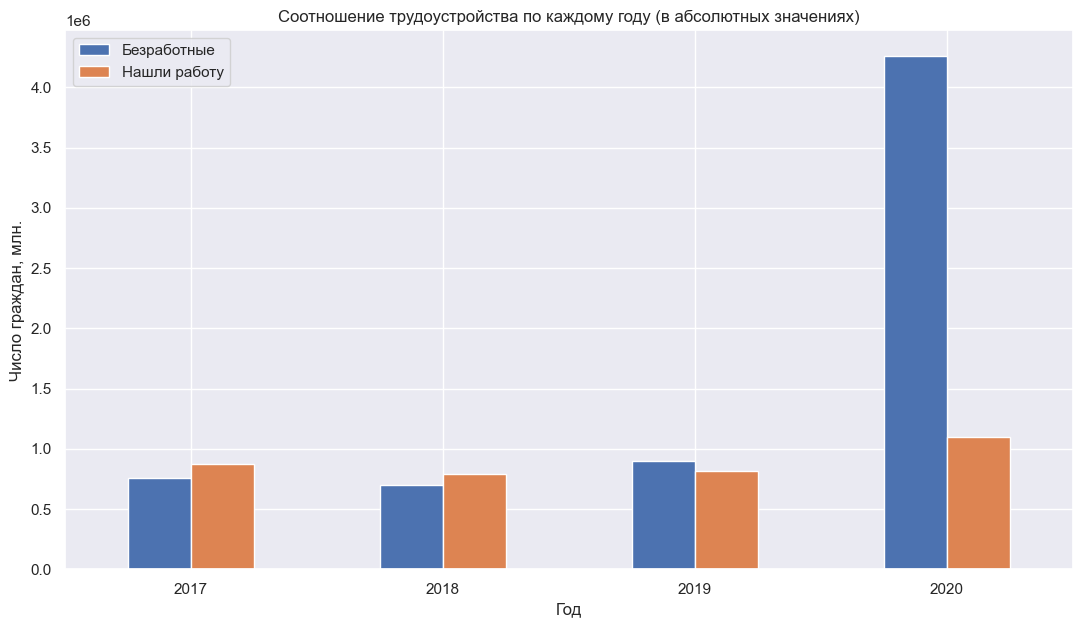

In [32]:
# Определим соотношение трудоустройства по каждому году (в абсолютных значениях)
find_new_job = df.pivot_table(index='year', columns='find_new_job', aggfunc='sum', values='count')
display(find_new_job)
find_new_job.plot(kind='bar', # присваиваю z значение find_new_job.plot, чтобы дальше использовать атрибут containers
               figsize = (13,7),
               title='Соотношение трудоустройства по каждому году (в абсолютных значениях)',
               rot = 0,
               xlabel='Год',
               ylabel='Число граждан, млн.')
plt.legend(loc='upper left')
plt.legend(['Безработные', 'Нашли работу'])
plt.show()

find_new_job,False,True
year,,
2017,46.5,53.5
2018,46.9,53.1
2019,52.4,47.6
2020,79.5,20.5


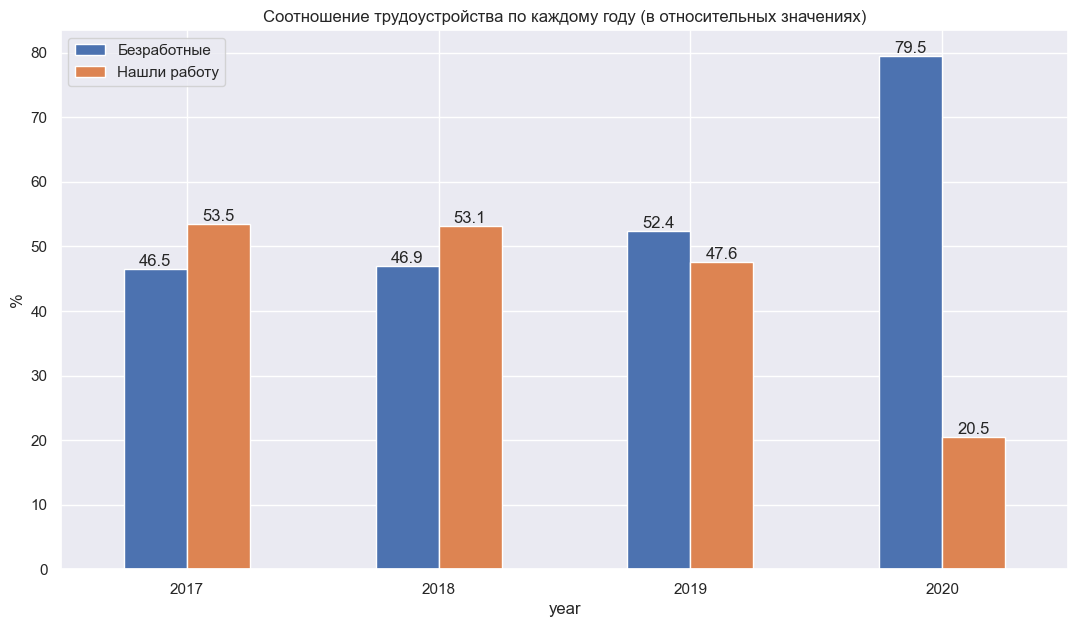

In [33]:
# Определим соотношение трудоустройства по каждому году (в относительных значениях)
find_new_job_year = df.pivot_table(index='year', columns='find_new_job', aggfunc='sum', values='count')
find_new_job_year = round(find_new_job_year.div(find_new_job_year.sum(axis=1), axis=0)*100,1) #1
display(find_new_job_year)
z = find_new_job_year.plot(kind='bar',
               figsize = (13,7),
                ylabel = '%',
               title='Соотношение трудоустройства по каждому году (в относительных значениях)',
                rot = 0)
plt.bar_label(z.containers[0]) #2
plt.bar_label(z.containers[1])
plt.legend(loc='upper left')
plt.legend(['Безработные', 'Нашли работу'])
plt.show()
#1 Пока думал, как компакто сделать таблицу сразу с процентами, наткнулся на такую штуку, как div.
# div() — это поэлементное деление DataFrame’а на другое значение (скаляр, серию или DataFrame).
# То есть каждая строка (год) делится на свою сумму — и в итоге получаются доли внутри года.
# P.s. Изначально хотел запихать в aggfunc lambda-функцию, но там получился какой-то мрак

#2 Хотел вывести все значения над столбцами, но без цикла. В целом с циклом я уже применял способ и хотел как то визуально код уменьшить.
# На просторах интернета нашел такой способ и, почитав документацию (и с помощью Нейросетей :), вроде разобрался

Мы можем заметить, что в 2017 и 2018 годах процент граждан, которые нашли работу, превышал 50%, что является хорошим результатом. В 2019 году этот показатель немного снизился (6%), но всё равно оставался выше среднего значения, рассчитанного ранее в задании 3. Во время пандемии COVID-19 (2020г.) процент граждан, которые смогли устроиться на работу, резко упал, что снизило среднее значение по всем годам. Таким образом, служба занятости в целом выполняет свою работу эффективно, если не учитывать такие непредсказуемые внешние факторы, как пандемия. Потому что возникли уникальные сложности: поиск работы был затруднен из-за карантинных мер и закрытия многих агентств занятости, а традиционные формы трудоустройства (офлайн-собеседования) стали недоступны.

### Анализ уровня образования груждан, обратившихся в службу занятости
Осуществите категоризацию по столбцам gender и education в соответствии с исходными данными. Определите с каким образованием в службу занятости обращаются гражданине, ранее официально не работавшие. Определите соотношение трудоустройства по каждому уровню образования.

In [34]:
df.head(1)

,id,district,region,month_application,changed_value,age,gender,education,hc_repeat,hc_didnotwork,find_new_job,count,year,month
0,1170,Дальневосточный федеральный округ,Амурская область,2017-01,False,52-57,0,4,True,False,False,1,2017,1


In [35]:
# Создадим для удобства два словаря с расшифровкой значений
gen = {
    1: "Мужской",
    0: "Женский"
}
edu = {
    1: "Начальное общее образование",
    2: "Основное общее образование", 
    3: "Среднее общее образование",
    4: "Среднее профессиональное образование",
    6: "Высшее образование",
    9: "Другое",
    0: "Нет данных"
}

education,Начальное общее образование,Основное общее образование,Среднее общее образование,Среднее профессиональное образование,Высшее образование,Другое
gender,,,,,,
Женский,3178,718452,1082139,1355321,1032408,170094
Мужской,4688,712647,1092147,1200647,528628,151758


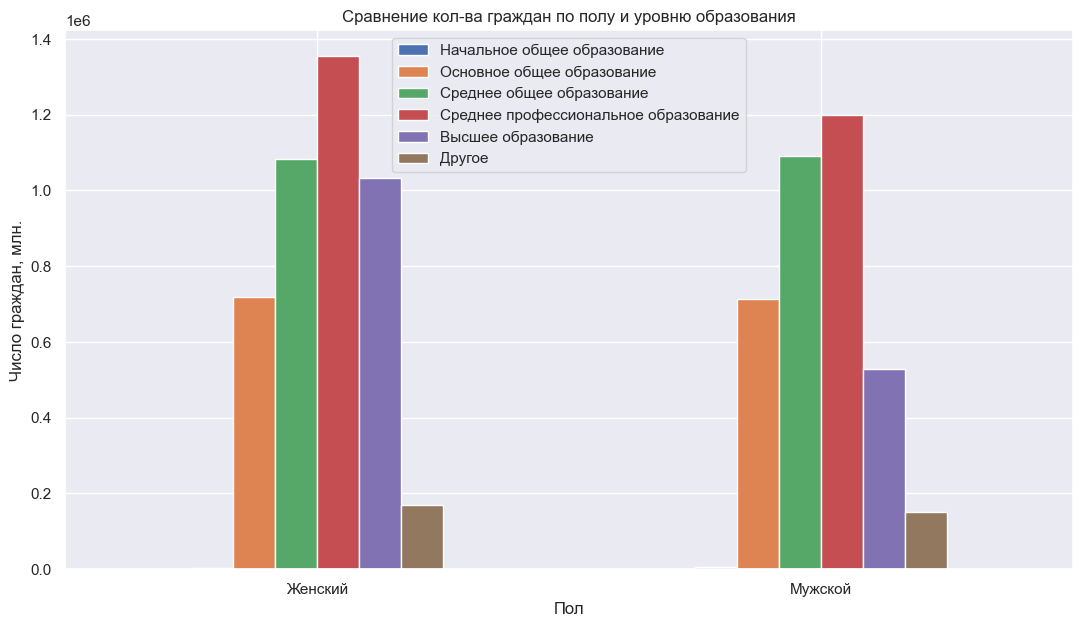

In [36]:
# Создадим сводную таблицу с категоризацией по полу и уровню образования
# Уберем строки, в которых нет данных по уровню образования
gender_education_didnotwork = df.query('education != 0').pivot_table(index='gender', columns='education', aggfunc='sum', values='count')
# Переименуем столбцы и индексы
gender_education_didnotwork.rename(columns=edu, inplace=True)
gender_education_didnotwork.rename(index=gen, inplace=True)
display(gender_education_didnotwork)
gender_education_didnotwork.plot(kind='bar',
               figsize = (13,7),
               title='Сравнение кол-ва граждан по полу и уровню образования',
               rot = 0,
               xlabel='Пол',
               ylabel='Число граждан, млн.')
plt.legend(loc='upper center')
plt.show()

education,Начальное общее образование,Основное общее образование,Среднее общее образование,Среднее профессиональное образование,Высшее образование,Другое
gender,,,,,,
Женский,782,215303,304746,196919,90973,67844
Мужской,774,172107,235813,159293,53944,52973


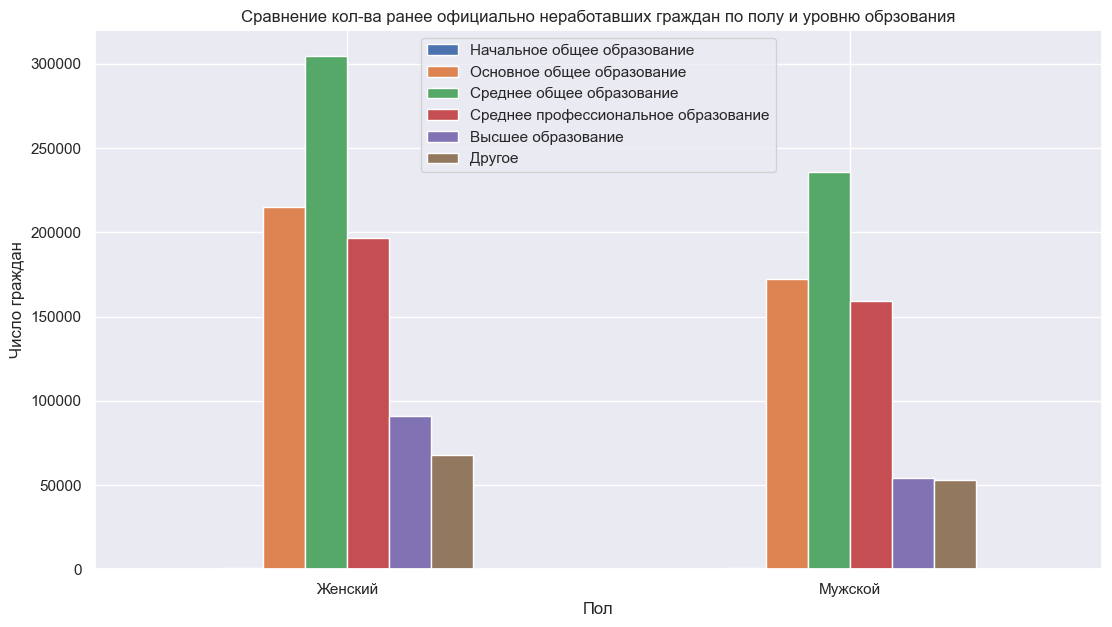

In [37]:
# Скопируем код из предыдущей ячейки и добавим фильтр
gender_education_didnotwork = df.query('education != 0 and hc_didnotwork').pivot_table(index='gender', columns='education', aggfunc='sum', values='count')
gender_education_didnotwork.rename(columns=edu, inplace=True)
gender_education_didnotwork.rename(index=gen, inplace=True)
display(gender_education_didnotwork)
gender_education_didnotwork.plot(kind='bar',
               figsize = (13,7),
               title='Сравнение кол-ва ранее официально неработавших граждан по полу и уровню обрзования',
               rot = 0,
               xlabel='Пол',
               ylabel='Число граждан')
plt.legend(loc='upper center')
plt.show()

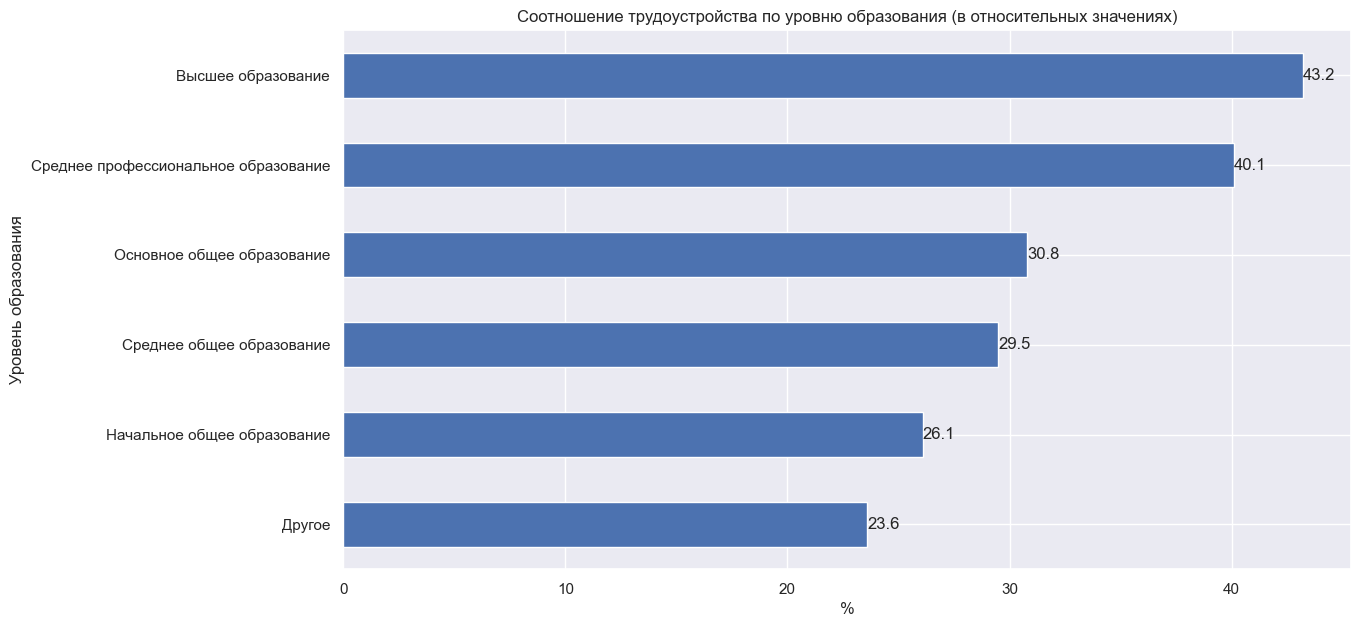

In [38]:
# Буду редактировать код из пункта 4, при этом уберу раздление по полу, т.к. это не ключевой признак в данном сравнении
find_new_job_edu = df.query('education != 0').pivot_table(index='education', columns='find_new_job', aggfunc='sum', values='count')
find_new_job_edu.rename(index=edu, inplace=True)
find_new_job_edu = round(find_new_job_edu.div(find_new_job_edu.sum(axis=1), axis=0)*100,1)
find_new_job_edu = find_new_job_edu[True].sort_values() # отсортируем нужный нам столбец и присвоим его
z = find_new_job_edu.plot(kind='barh',
               figsize = (13,7),
               ylabel = 'Уровень образования',
               xlabel = '%',
               title='Соотношение трудоустройства по уровню образования (в относительных значениях)',
               rot = 0)
plt.bar_label(z.containers[0])
plt.show()

Наиболее высокий показатель трудоустройства наблюдается среди граждан с высшим образованием — 43,2%. Это свидетельствует о том, что наличие высшего образования значительно повышает шансы найти работу. Немного уступают им лица со средним профессиональным образованием (40,1%), что также подтверждает высокую востребованность специалистов рабочих и технических профессий.
Далее следуют граждане с основным общим (30,8%) и средним общим образованием (29,5%), у которых шансы на трудоустройство заметно ниже. Это объясняется отсутствием профессиональной квалификации и ограниченным выбором доступных вакансий.
Наименее успешно трудоустраиваются граждане с начальным общим образованием (26,1%) и те, кто попадает в категорию «другое» (23,6%). Эти данные отражают зависимость уровня занятости от уровня образования: чем выше образовательная подготовка, тем выше вероятность найти работу.

### Исследование безработицы в России за 2020 год

In [39]:
# Создадим новый датафрейм с данными только за 11 месяцев 2020 года
data = df.query('year == 2020 and month != 12')

#### Динамика числа безработных и нашедших работу за 2020 год по месяцам

find_new_job,False,True
month,,
1,98098,63615
2,96326,53040
3,104349,49817
4,720765,299564
5,577112,220721
6,622049,153530
7,545431,112190
8,465066,73088
9,374197,43106


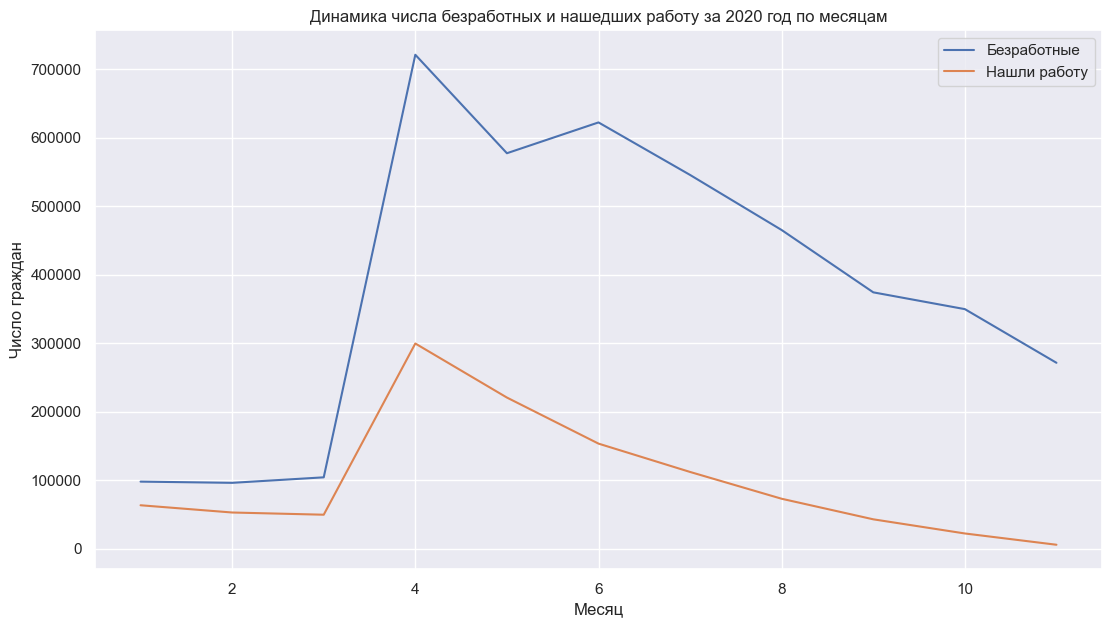

In [40]:
find_new_job_month = data.pivot_table(index='month', columns='find_new_job', aggfunc='sum', values='count')
display(find_new_job_month)
find_new_job_month.plot(figsize = (13,7), 
                        title='Динамика числа безработных и нашедших работу за 2020 год по месяцам',
                        xlabel='Месяц',
                        ylabel='Число граждан')
plt.legend(['Безработные', 'Нашли работу']) # Поменял названия графиков в легенде
plt.show()

В начале года, особенно в первые месяцы, наблюдался резкий и значительный рост численности безработных, что было напрямую связано с началом пандемии COVID-19 и введением ограничительных мер, парализовавших многие отрасли экономики. Этот пик пришелся на четвертый месяц, когда количество обратившихся в службу занятости достигло максимальных значений, приближаясь к 600-700 тысячам человек. С марта как раз начался карантин. Однако начиная с этого момента ситуация начала постепенно стабилизироваться: кривая безработицы пошла на спад, что свидетельствовало о постепенной адаптации рынка труда к новым условиям и, вероятно, о результативности мер государственной поддержки.

#### Процент трудоустройства по гендерной принадлежности

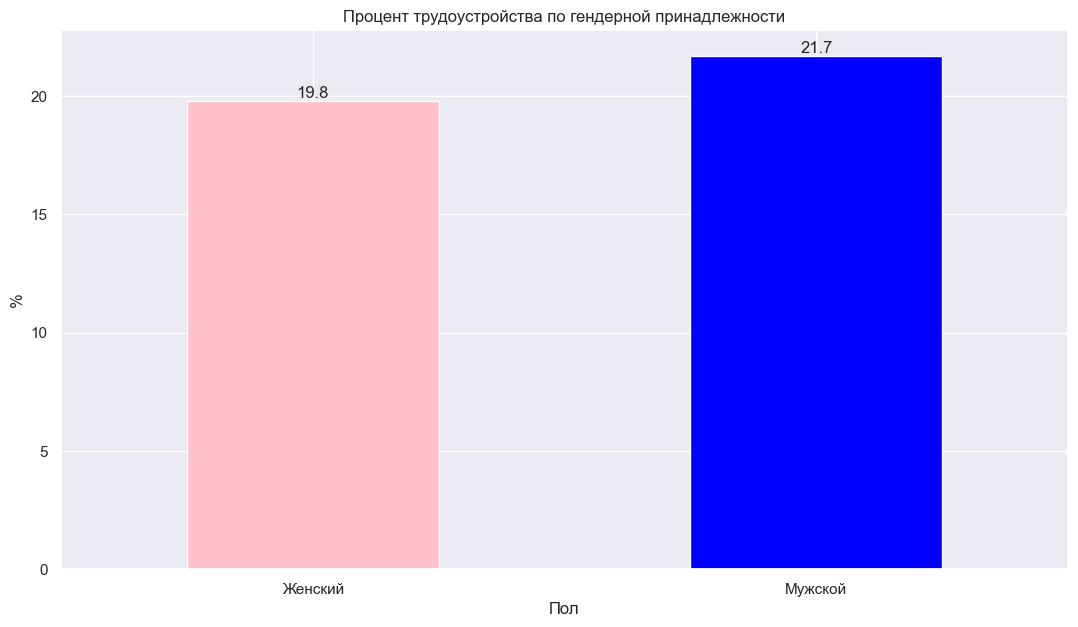

In [41]:
find_new_job_gen = data.pivot_table(index='gender', columns='find_new_job', aggfunc='sum', values='count')
find_new_job_gen.rename(index=gen, inplace=True)
find_new_job_gen = round(find_new_job_gen.div(find_new_job_gen.sum(axis=1), axis=0)*100,1)
find_new_job_gen = find_new_job_gen[True]
z = find_new_job_gen.plot(kind='bar',
               figsize = (13,7),
               ylabel = '%',
               xlabel = 'Пол',
               title='Процент трудоустройства по гендерной принадлежности',
               rot = 0,
               color = ['pink', 'blue'])
plt.bar_label(z.containers[0])
plt.show()

Мы видим небольшой перевес в сторону мужчин, но этот перевес незначильный. Таким образом можно сделать вывод, что пол не влияет на трудоустройство.

#### Число обращений в службу занятости по федеральным округам

,count
district,
Приволжский федеральный округ,1048536
Центральный федеральный округ,1029581
Сибирский федеральный округ,718075
Северо-Кавказский федеральный округ,701325
Южный федеральный округ,595894
Северо-Западный федеральный округ,477798
Уральский федеральный округ,461222
Дальневосточный федеральный округ,289224


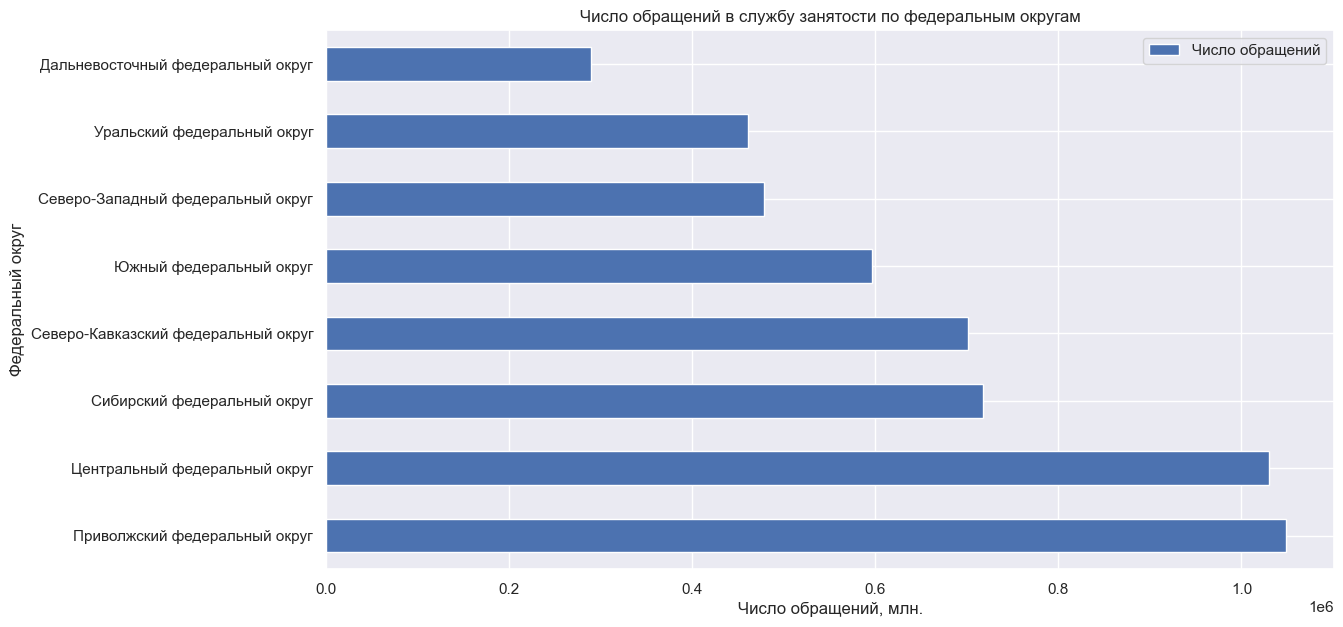

In [42]:
region_count = data.pivot_table(index='district', aggfunc='sum', values='count').sort_values(by='count', ascending=False)
display(region_count)
region_count.plot(kind='barh',
               figsize = (13,7),
               ylabel = 'Федеральный округ',
               xlabel = 'Число обращений, млн.',
               title='Число обращений в службу занятости по федеральным округам',
               rot = 0)
plt.legend(['Число обращений'])
plt.show()

Лидером по количеству обращений является Приволжский федеральный округ, показатель которого значительно превышает все остальные регионы и составляет 1,05 млн. обращений. На втором месте расположился Центральный федеральный округ с результатом около миллиона, что также является весьма высоким показателем. Сибирский и Северо-Кавказский федеральные округа демонстрируют средние значения в диапазоне 0,6-0,8 млн., тогда как Южный и Северо-Западный округа показывают более низкие результаты около 0,45 млн. Наименьшее количество обращений зафиксировано в Уральском и Дальневосточном федеральных округах, где показатели примерно 0,3 млн. Такое распределение четко указывает на существенную региональную дифференциацию в уровне обращаемости граждан в службы занятости, что может быть связано с различной экономической ситуацией, структурой рынка труда и уровнем безработицы в разных частях страны, при этом наиболее сложная ситуация складывается в регионах Приволжья и Центральной России.

#### Разброс числа объявлений по регионам

,count
region,
г. Москва,296258
Чеченская Республика,224273
Московская область,210040
Краснодарский край,198111
Республика Башкортостан,185516
...,...
Сахалинская область,6431
г. Севастополь,5997
Магаданская область,3554


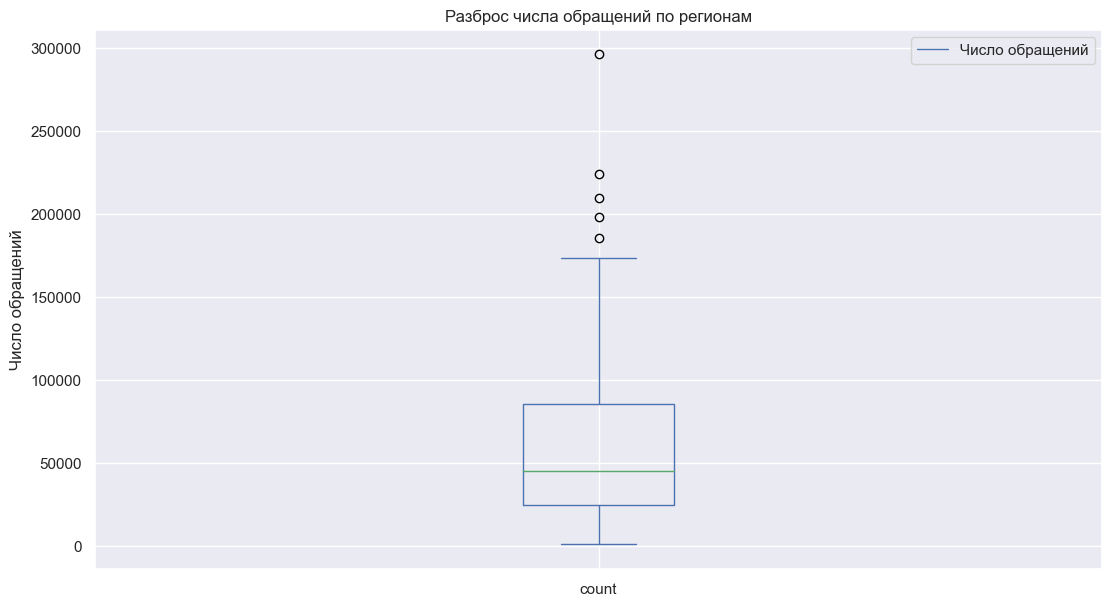

In [43]:
region_count = data.pivot_table(index='region', aggfunc='sum', values='count').sort_values(by='count', ascending=False)
display(region_count)
region_count.plot(kind='box',
               figsize = (13,7),
               ylabel = 'Число обращений',
               title='Разброс числа обращений по регионам',
               rot = 0)
plt.legend(['Число обращений'])
plt.show()
# не понял как убрать count внизу графика

Лидером по количеству обращений является Москва, где было зафиксировано 296258 случаев, что значительно превышает показатели других субъектов федерации. На втором месте находится Чеченская Республика с 224273 обращениями, что свидетельствует о серьезных проблемах с занятостью в этих регионах. Московская область занимает третью позицию с 210040 обращениями, демонстрируя тем самым, что проблемы с трудоустройством характерны не только для столицы, но и для всего центрального региона страны.
В свою очередь график показывает значительную вариацию числа обращений между разными регионами России. Распределение является неравномерным и скошенным - большинство регионов имеют относительно невысокие показатели обращаемости, в то время как небольшая группа субъектов демонстрирует экстремально высокие значения. Такой характер распределения свидетельствует о существенной региональной дифференциации на рынке труда.
Наличие выбросов указывает на то, что в отдельных субъектах федерации сложилась особенно напряженная ситуация с занятостью.
Медианное значение числа обращений значительно ниже среднего, что подтверждает вывод о концентрации проблем безработицы в ограниченном числе регионов. Большинство же субъектов федерации имеют показатели в пределах типичного диапазона.
Подобная картина распределения обращений характерна для ситуаций, когда региональные рынки труда по-разному реагируют на экономические шоки, что могло быть следствием пандемийных ограничений 2020 года, имевших неодинаковое влияние на различные отрасли экономики и, соответственно, на регионы с разной производственной специализацией.

#### Число обращений в службу занятости в Северо-Западном федеральном округе по регионам

,count
region,
г. Санкт-Петербург,156668
Калининградская область,52451
Вологодская область,50283
Ленинградская область,49637
Архангельская область,42056
Республика Коми,36318
Республика Карелия,27755
Мурманская область,23166
Новгородская область,20088


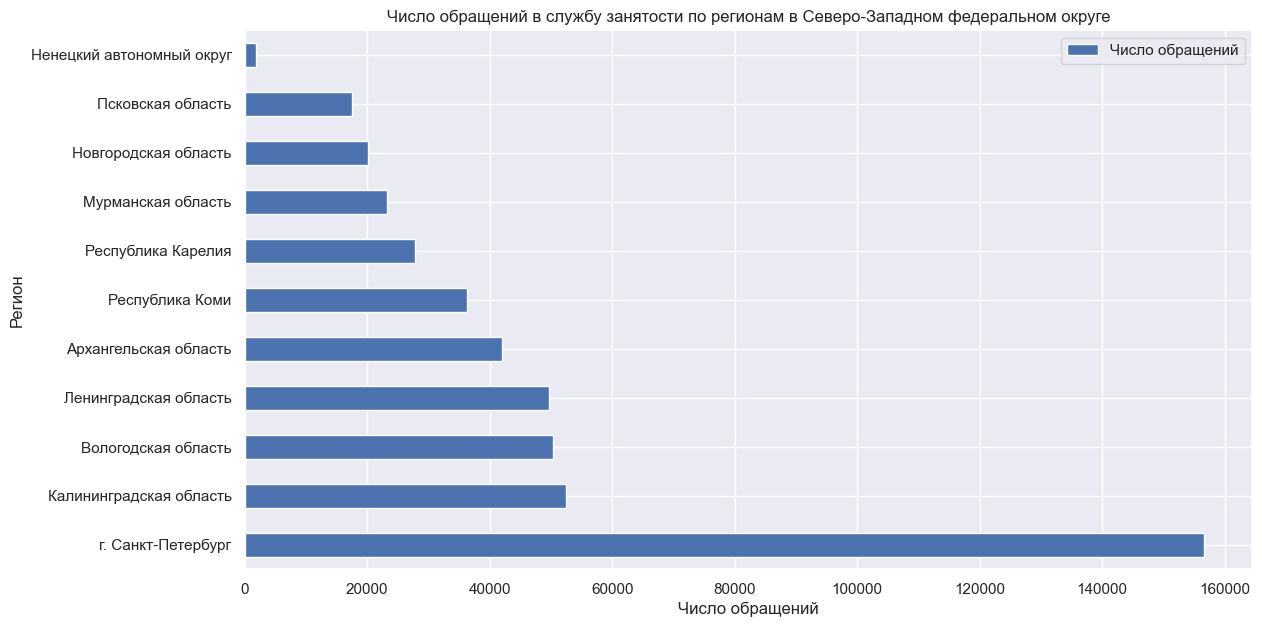

In [44]:
region_count_distr = data.query('district == "Северо-Западный федеральный округ"').pivot_table(index='region', aggfunc='sum', values='count').sort_values(by='count', ascending=False)
display(region_count_distr)
region_count_distr.plot(kind='barh',
               figsize = (13,7),
               ylabel = 'Регион',
               xlabel = 'Число обращений',
               title='Число обращений в службу занятости по регионам в Северо-Западном федеральном округе',
               rot = 0)
plt.legend(['Число обращений'])
plt.show()

Как и ожидалось, Санкт-Петербург - лидер по количеству обращений в службу занятости, т.к. население СПб сильно больше других регионов. Остальные регионы держат уровень обращений примерно на медианном.

#### Процент трудоустройства по федеральным округам

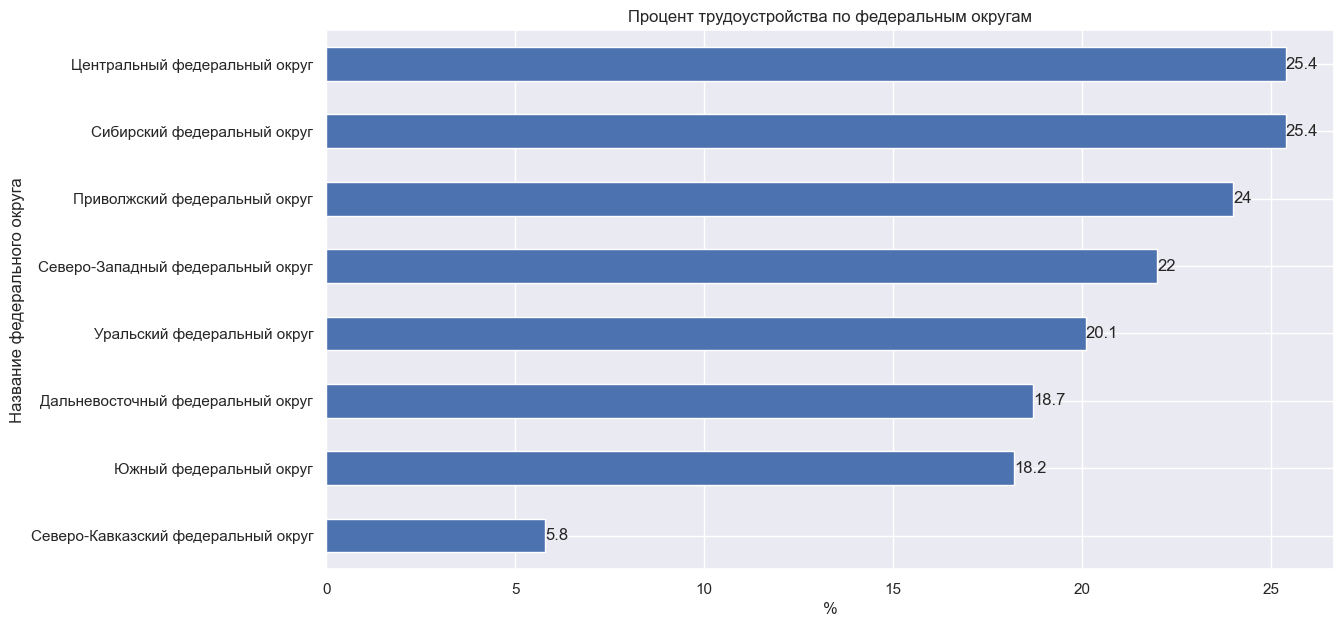

In [45]:
find_new_job_dist = data.pivot_table(index='district', columns='find_new_job', aggfunc='sum', values='count')
find_new_job_dist = round(find_new_job_dist.div(find_new_job_dist.sum(axis=1), axis=0)*100,1)
find_new_job_dist = find_new_job_dist[True].sort_values()
z = find_new_job_dist.plot(kind='barh',
               figsize = (13,7),
               ylabel = 'Название федерального округа',
               xlabel = '%',
               title='Процент трудоустройства по федеральным округам',
               rot = 0)
plt.bar_label(z.containers[0])
plt.show()

Наиболее эффективно службы занятости работали в Центральном и Сибирском федеральных округах, где каждый четвертый обратившийся смог найти работу - уровень трудоустройства здесь составил 25,4%. Чуть ниже, но также выше среднего показателя эффективность демонстрируют Приволжский (24%) и Северо-Западный (22%) округа. Уральский федеральный округ с результатом 20,1% находится на среднем уровне, в то время как Южный (18,2%) и Дальневосточный (18,7%) округа показывают результаты ниже среднего. Особенно тревожная ситуация сложилась в Северо-Кавказском федеральном округе, где уровень трудоустройства через службы занятости составляет лишь 5,8%, что более чем в четыре раза ниже показателей лидирующих округов. Такой значительный разрыв в эффективности трудоустройства между регионами свидетельствует о серьезных структурных проблемах на рынке труда Северного Кавказа, где, вероятно, сочетаются такие факторы, как недостаточное количество вакансий, несоответствие квалификации безработных требованиям работодателей и ограниченные возможности для создания новых рабочих мест. В целом картина показывает существенную региональную дифференциацию в эффективности работы служб занятости, что требует разработки дифференцированных подходов к политике занятости в различных федеральных округах страны.

#### Процент трудоустройства по регионам для каждого федерального округа

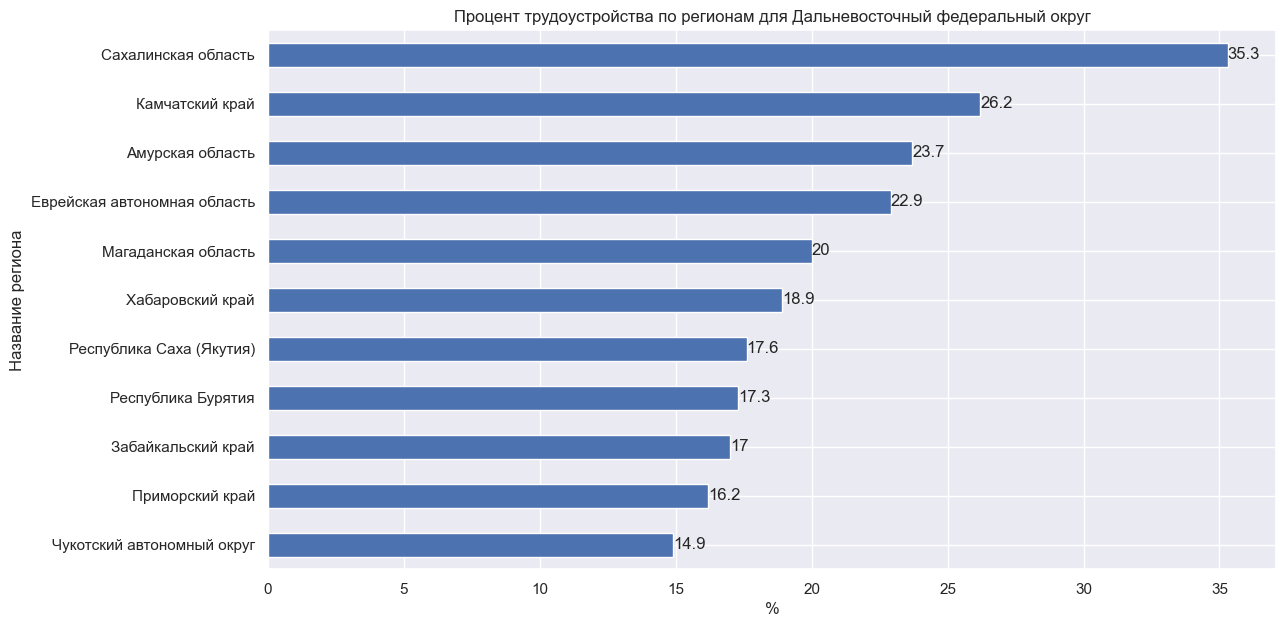

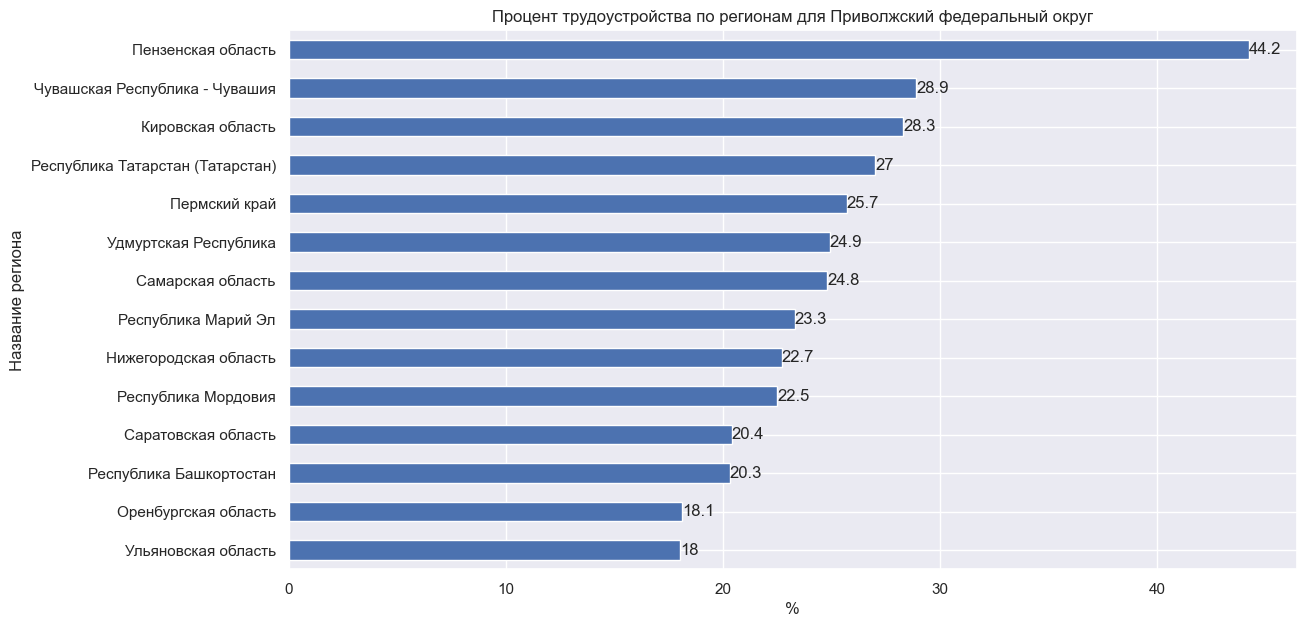

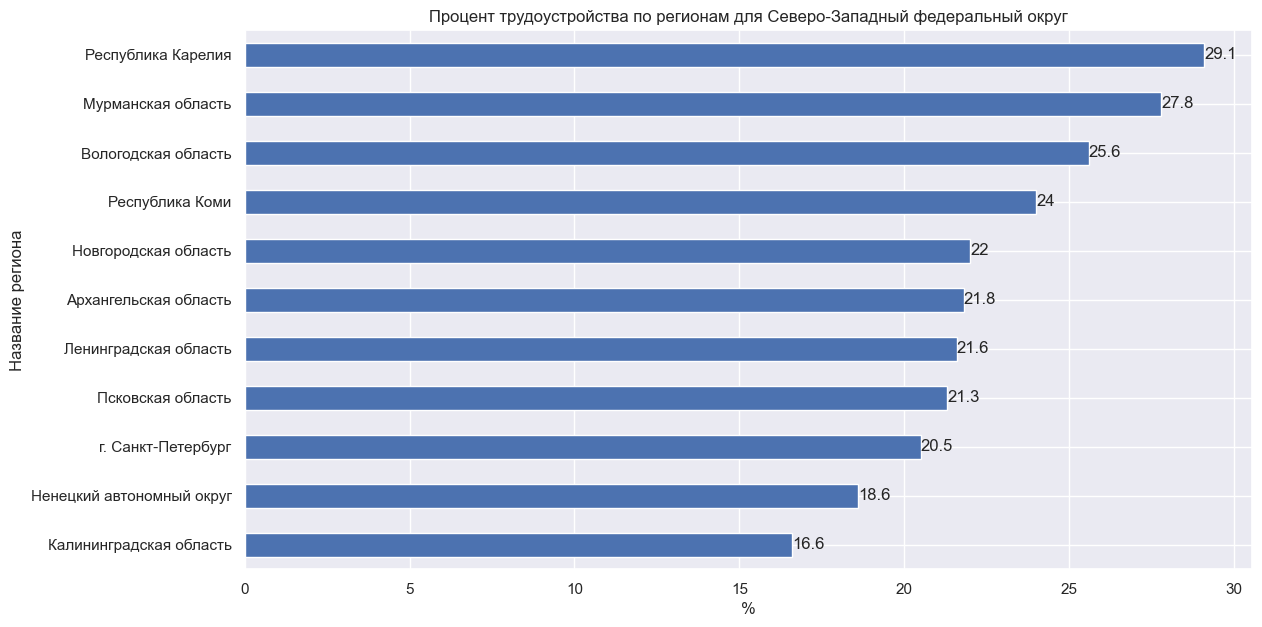

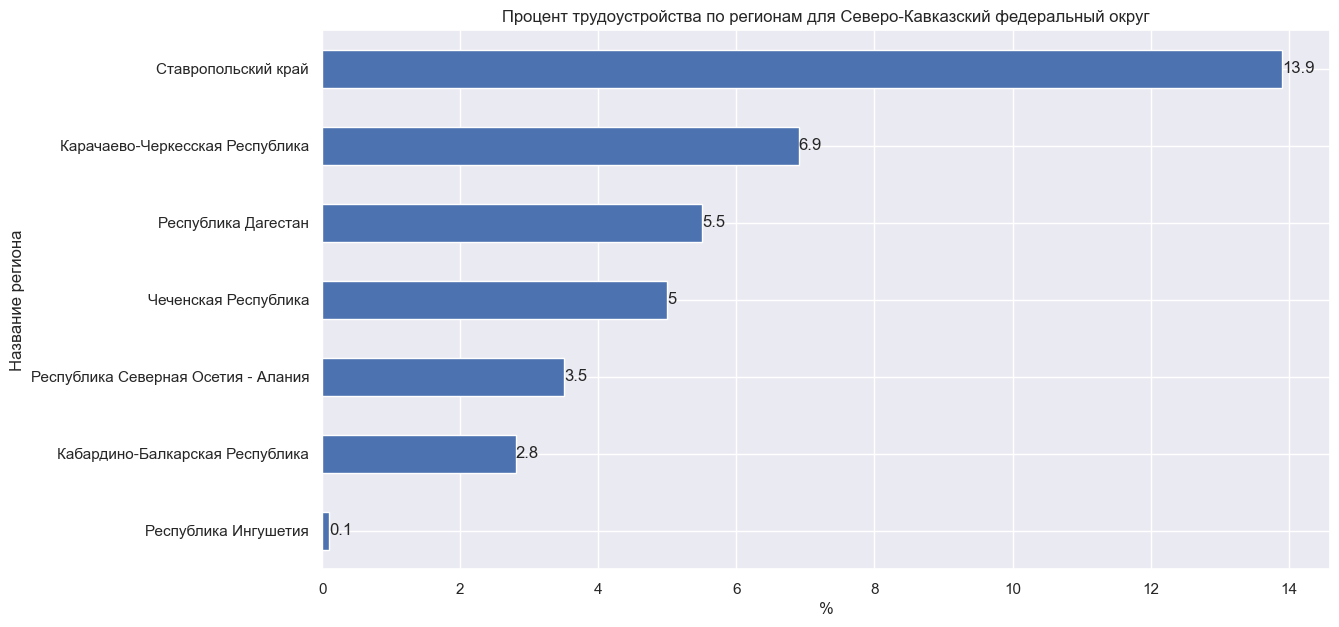

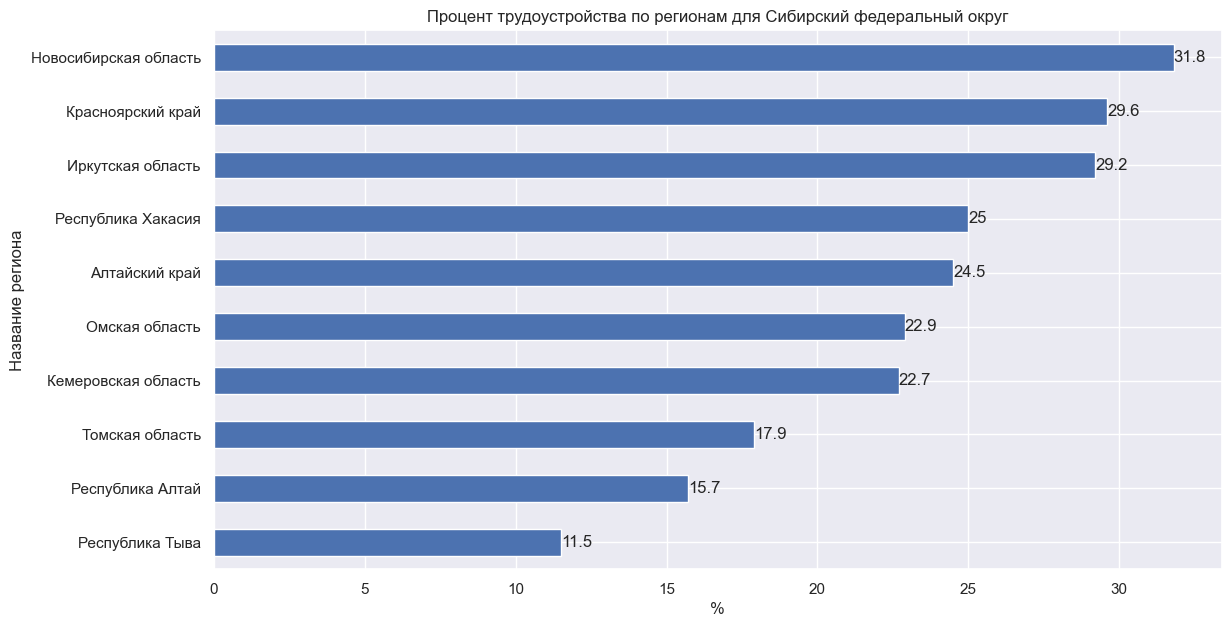

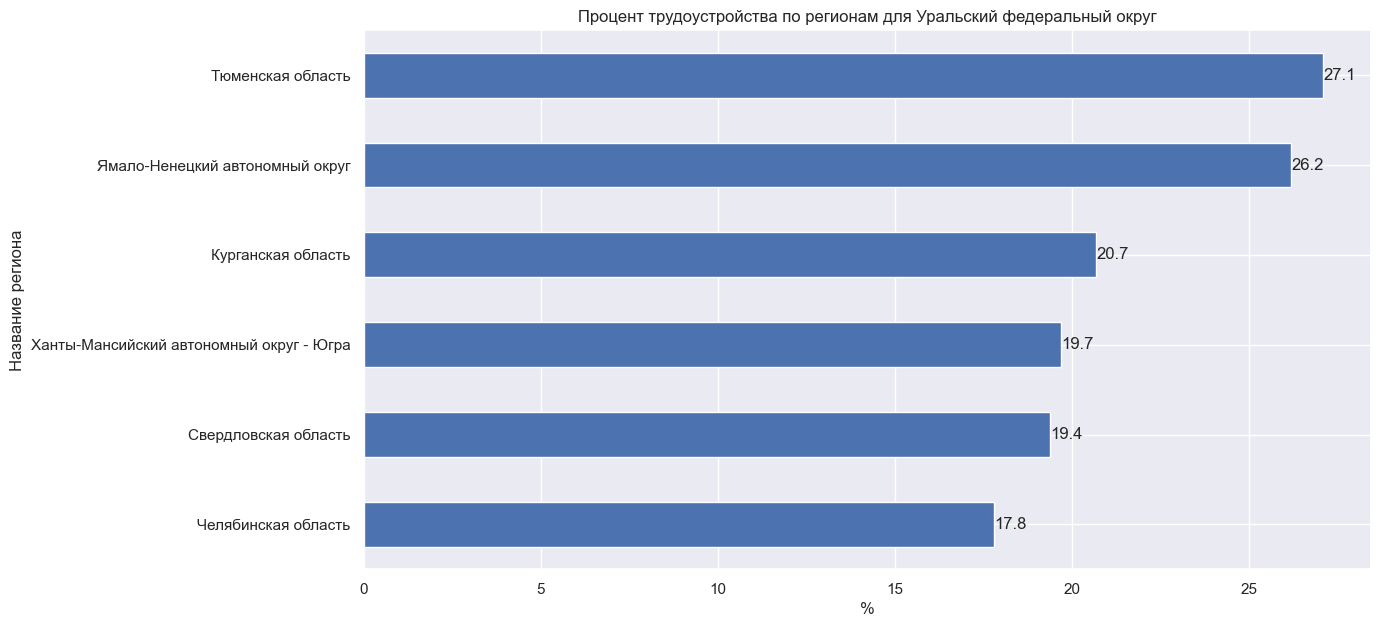

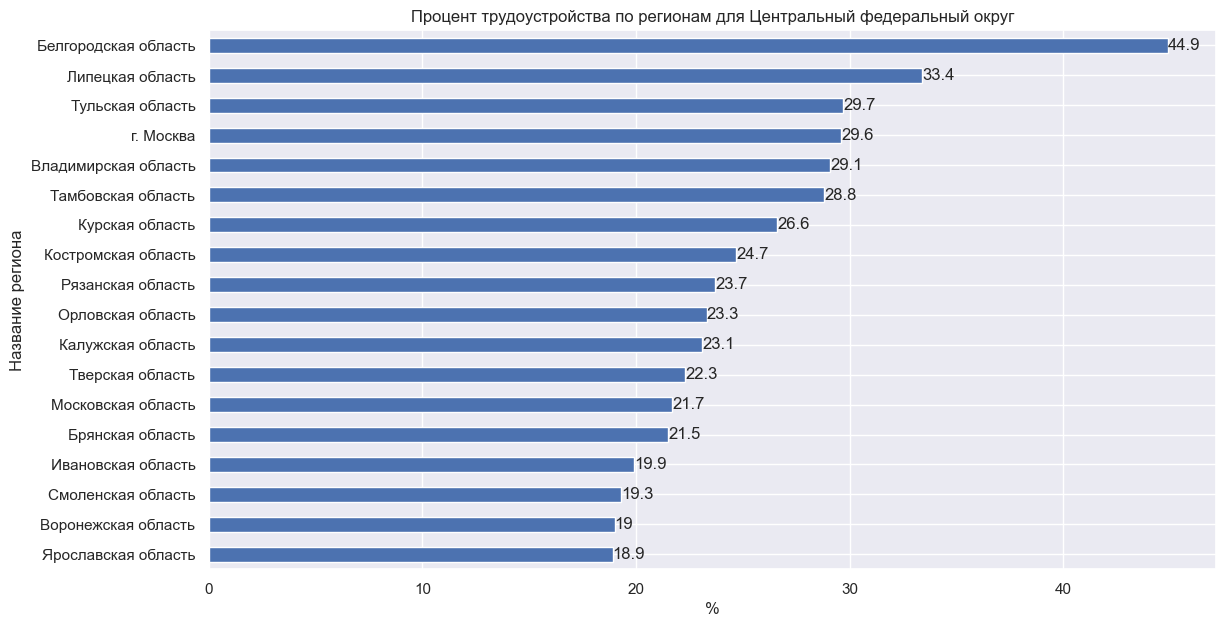

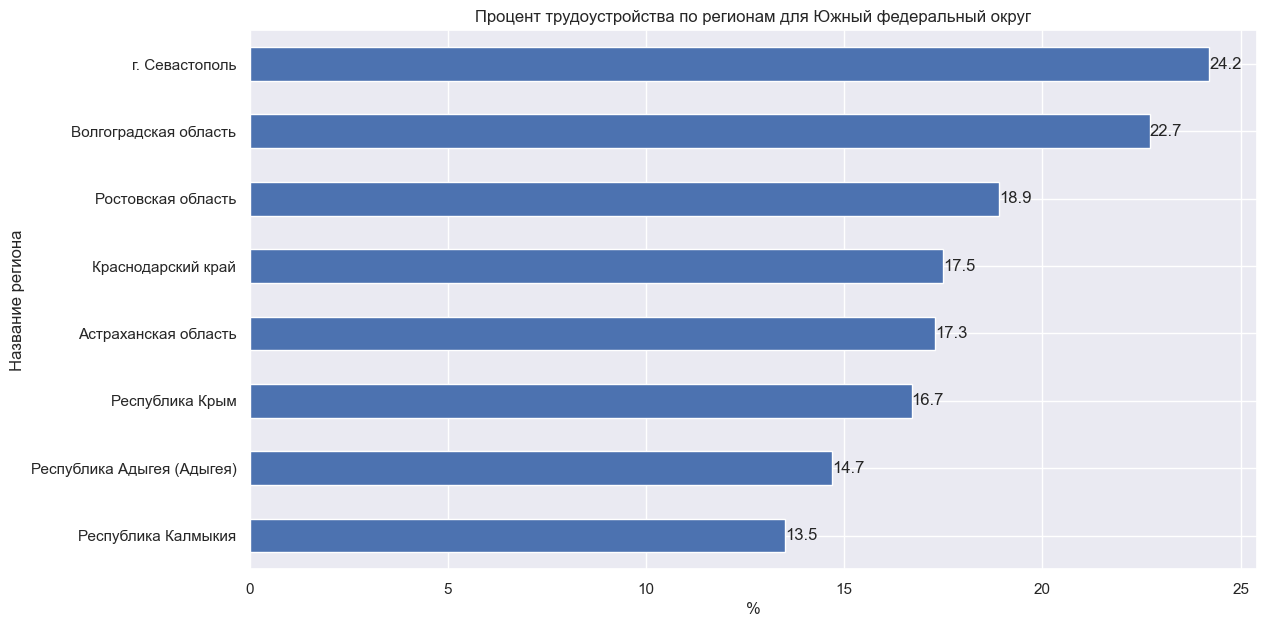

In [46]:
def find_new_job_per(dist):
    # Сначала пытался сделать через query, но у меня не получилось, и я вернулся к старым добрым квадратным скобкам
    pivot = data[data['district']==dist].pivot_table(index='region', columns='find_new_job', aggfunc='sum', values='count')
    pivot = round(pivot.div(pivot.sum(axis=1), axis=0)*100,1)
    pivot = pivot[True].sort_values()
    z = pivot.plot(kind='barh',
               figsize = (13,7),
               ylabel = 'Название региона',
               xlabel = '%',
               title=f'Процент трудоустройства по регионам для {dist}',
               rot = 0)
    plt.bar_label(z.containers[0])
    return plt.show()
for i in data['district'].unique():
    find_new_job_per(i)
    print()

### Вывод

В ходе проведенного исследования был осуществлен комплексный анализ рынка труда и динамики безработицы в России на основе данных службы занятости. Работа началась с изучения общей динамики обращений граждан в службы занятости, где был выявлен циклический характер с сезонными колебаниями и определен тренд увеличения доли повторных обращений, что указывает на формирование устойчивой группы длительно безработных. Далее был проведен детальный анализ возрастной структуры обращающихся, который показал концентрацию безработицы в наиболее продуктивных возрастных группах от 25 до 45 лет.

Особое внимание было уделено эффективности трудоустройства через службы занятости - анализировались как абсолютные показатели трудоустройства, так и относительные проценты по годам, что позволило выявить периоды наибольшей и наименьшей эффективности работы служб занятости. Значительная часть исследования была посвящена анализу социально-демографических характеристик безработных, где установлена четкая зависимость между уровнем образования и вероятностью трудоустройства, при этом наибольшие сложности с поиском работы испытывают лица с начальным и иными видами образования.

Глубокому анализу был подвергнут кризисный 2020 год, связанный с пандемией COVID-19, когда наблюдался резкий всплеск безработицы весной с последующей постепенной стабилизацией в летне-осенний период. Географический анализ выявил существенную региональную дифференциацию как по уровню обращаемости в службы занятости, так и по эффективности трудоустройства. Наибольшая нагрузка на службы занятости отмечается в густонаселенных округах, тогда самые низкие показатели трудоустройства зафиксированы в Северо-Кавказском федеральном округе.

Метод визуализации через boxplot подтвердил гипотезу о значительном разбросе показателей между регионами с выделением статистических аутсайдеров. Завершающим этапом стал детальный анализ внутри каждого федерального округа, который показал, что даже в относительно благополучных округах имеются регионы с крайне низкими показателями трудоустройства. Все этапы исследования сопровождались соответствующими визуализациями - линейными графиками, столбчатыми диаграммами и boxplot, что обеспечило наглядность представления результатов и позволило сделать обоснованные выводы об эффективности работы служб занятости в России.